<a href="https://colab.research.google.com/github/KudjoJedidiah/ATF-Course-Notebooks/blob/main/Week1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd

np.random.seed(42)
print("Libraries loaded successfully")

Libraries loaded successfully


In [ ]:
# Example: Predicting daily activities (represented as numbers)
# 0=Sleep, 1=Work, 2=Exercise, 3=Social, 4=Leisure

historical_activities = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]

def calculate_probabilities(sequence):
  counts=Counter(sequence)
  total=len(sequence)
  probabilities={activity:count/total for activity,count in counts.items()}
  return probabilities


In [ ]:
probs=calculate_probabilities(historical_activities)
print(probs)

{0: 0.2, 1: 0.4, 2: 0.13333333333333333, 3: 0.13333333333333333, 4: 0.13333333333333333}


In [ ]:
activity_names = {0: 'Sleep', 1: 'Work', 2: 'Exercise', 3: 'Social', 4: 'Leisure'}

print("Activity Probabilities:")
for activity,prob in sorted(probs.items()):
  print(f"{activity_names[activity]}: {prob:.2%}")

Activity Probabilities:
Sleep:20.00%
Work:40.00%
Exercise:13.33%
Social:13.33%
Leisure:13.33%


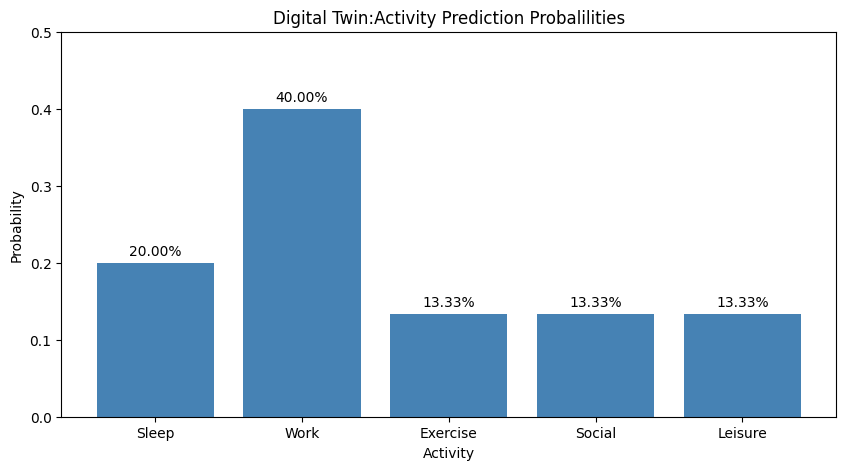

In [ ]:
plt.figure(figsize=(10,5))
activities=[activity_names[k] for k in sorted(probs.keys())]
probabilities=[probs[k] for k in sorted(probs.keys())]
plt.bar(activities,probabilities,color='steelblue')
plt.xlabel("Activity")
plt.ylabel("Probability")
plt.title("Digital Twin:Activity Prediction Probalilities")
plt.ylim(0,0.5)
for i,v in enumerate(probabilities):
  plt.text(i,v+0.01,f"{v:.2%}",ha='center')
plt.show()

In [ ]:
def calculate_conditional_probabilities(sequence):
  transitions={}
  for i in range(len(sequence)-1):
    current=sequence[i]
    next_activity=sequence[i+1]

    if current not in transitions:
      transitions[current]=[]
    transitions[current].append(next_activity)

  conditional_probs={}
  for current,next_list in transitions.items():
    counts=Counter(next_list)
    total=len(next_list)
    conditional_probs[current]={activity:count/total for activity,count in counts.items()}
  return conditional_probs

In [ ]:
cond_probs=calculate_conditional_probabilities(historical_activities)
print(cond_probs)

{0: {1: 1.0}, 1: {2: 0.3333333333333333, 3: 0.3333333333333333, 4: 0.3333333333333333}, 2: {1: 1.0}, 3: {1: 1.0}, 4: {0: 1.0}}


In [ ]:
print("Conditional Probabilities:P(Next|Current)\n")
for current_activity,next_probs in cond_probs.items():
  print(f"After {activity_names[current_activity]}:")
  for next_activity,prob in sorted(next_probs.items()):
    print(f" -> {activity_names[next_activity]}: {prob:.2%}")
  print()

Conditional Probabilities:P(Next|Current)

After Sleep:
 -> Work: 100.00%

After Work:
 -> Exercise: 33.33%
 -> Social: 33.33%
 -> Leisure: 33.33%

After Exercise:
 -> Work: 100.00%

After Social:
 -> Work: 100.00%

After Leisure:
 -> Sleep: 100.00%



NEURAL NETWORK BASICS


In [ ]:
def sigmoid(x):
  return 1/(1+np.exp(-x))

def perceptron(inputs,weights,bias):
  weighted_sum=np.dot(inputs,weights)+bias
  output=sigmoid(weighted_sum)
  return output



Example: Predicting if someone will exercise based on features
Features: [hours_of_sleep, free_time_hours, energy_level (0-1)]

In [ ]:
person_features = np.array([7, 2, 0.8])  # 7 hours sleep, 2 hours free time, high energy
weights=np.array([0.3,0.5,0.7])
bias=-0.5
prediction=perceptron(person_features,weights,bias)
print(f"Prediction: {prediction:.2%}")
print(f"Prediction:{'Will exercise' if prediction >0.5 else 'will not exercise'}")

Prediction: 95.93%
Prediction:Will exercise


In [ ]:
test_cases = [
    np.array([4, 2, 0.8]),  # Low sleep
    np.array([7, 4, 0.8]),  # More free time
    np.array([7, 2, 0.3]),  # Low energy
]

for i in test_cases:
  prediction=perceptron(i,weights,bias)
  print(f"Prediction: {prediction:.2%}")
  print(f"Prediction:{'Will exercise' if prediction >0.5 else 'will not exercise'}")

Prediction: 90.55%
Prediction:Will exercise
Prediction: 98.46%
Prediction:Will exercise
Prediction: 94.32%
Prediction:Will exercise
